# Power Plant Flexibility: Ramping, Minimum Load and Operating Times

In all notebooks so far, the gas power plants could change their output from one hour to the next without any limit: from zero to full load and back. Real power plants are less flexible. This notebook adds three typical limits:

| Limit | Parameters | Problem type |
|---|---|---|
| How fast the output can change | `rampUpMax`, `rampDownMax` | linear (LP) |
| A minimum output while running | `partLoadMin`, `bigM` | mixed-integer (MILP) |
| Minimum times on and off | `fn.ConversionDynamic` with `upTimeMin`, `downTimeMin` | mixed-integer (MILP) |

We apply each of them to the gas power plants of the basic tutorial and compare their operation.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fine as fn
from tutorialHelpers import COLORS, buildBasicTutorialModel

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

The models with integer variables are solved up to a gap of 1 %: the solver stops as soon as its solution is proven to cost at most 1 % more than the optimum (see the [Binary Decisions notebook](43_binary_decisions.ipynb)). The name of this setting depends on the solver:

In [2]:
if fn.ImplementedSolvers.STANDARD_SOLVER.value == "gurobi":
    mipGap = "MIPGap=0.01"
else:
    mipGap = "mip_rel_gap=0.01"

To compare the variants, we look at the operation of the gas power plants in the south in 2040, relative to their capacity. The optimization used typical days, so we compare the hours within each day, where the limits apply.

In [3]:
def gasPlantOperation(esM, region="south", year=2040):
    """Hourly operation of the gas power plants relative to their capacity (365 x 24)."""
    modelingClass = esM.componentModelingDict[
        "ConversionDynamicModel"
        if "ConversionDynamicModel" in esM.componentModelingDict
        else "ConversionModel"
    ]
    operation = modelingClass.getOptimalValues("operationVariablesOptimum", ip=year)[
        "values"
    ].loc[("Gas power plants", region)]
    capacity = modelingClass.getOptimalValues("capacityVariablesOptimum", ip=year)[
        "values"
    ].loc["Gas power plants", region]
    return operation.to_numpy().reshape(365, 24) / capacity


def describeOperation(esM):
    """Key figures of the operation of the gas power plants in the south in 2040."""
    load = gasPlantOperation(esM)
    running = load > 1e-3
    starts = (running[:, 1:] & ~running[:, :-1]).sum()
    return {
        "Largest change from one hour to the next": np.abs(np.diff(load, axis=1)).max(),
        "Lowest output while running": load[running].min(),
        "Starts per year (within the days)": starts,
        "Total cost [billion Euro]": esM.objectiveValue / 1000,
    }

## 1. The reference: no limits

In [4]:
esM = buildBasicTutorialModel()
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

comparison = {"No limits": describeOperation(esM)}
operationPerVariant = {"No limits": gasPlantOperation(esM)}

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (71 outputs left out)

Solved with barrier


    3402    5.9738972e+05   0.000000e+00   0.000000e+00      1s


Solved in 3402 iterations and 0.62 seconds (0.88 work units)


Optimal objective  5.973897241e+05


## 2. Ramping limits with `rampUpMax` and `rampDownMax`

**`rampUpMax`** and **`rampDownMax`** limit how much the operation of a conversion may rise or fall from one time step to the next, relative to its capacity. With hourly time steps and a value of 0.2, the output can change by at most 20 % of the capacity per hour, so going from zero to full load takes 5 hours. The limits are linear constraints, so the problem stays an LP.

In [5]:
esM = buildBasicTutorialModel()
esM.updateComponent("Gas power plants", {"rampUpMax": 0.2, "rampDownMax": 0.2})
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

comparison["Ramping limits"] = describeOperation(esM)
operationPerVariant["Ramping limits"] = gasPlantOperation(esM)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (70 outputs left out)

Solved with barrier


    2754    6.0058657e+05   0.000000e+00   0.000000e+00      1s


Solved in 2754 iterations and 0.78 seconds (0.89 work units)


Optimal objective  6.005865698e+05


## 3. A minimum load with `partLoadMin`

Many power plants cannot run at very low output; below a minimum load, they have to be switched off. **`partLoadMin`** sets this minimum as a share of the capacity: here, 40 %. In every hour, the plant is either off or runs with at least 40 % of its capacity.

This either-or decision needs a binary variable per region and hour, so the problem becomes a MILP. FINE also needs **`bigM`**, an upper limit for the hourly operation, which has to be larger than the operation can ever be, but should not be much larger. The gas power plants have about 30 GW per region, so we use 40 GW.

In [6]:
esM = buildBasicTutorialModel()
esM.updateComponent("Gas power plants", {"partLoadMin": 0.4, "bigM": 40})
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True, optimizationSpecs=mipGap)

comparison["Minimum load"] = describeOperation(esM)
operationPerVariant["Minimum load"] = gasPlantOperation(esM)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter MIPGap to value 0.01


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


... (31 outputs left out)

Thread count was 3 (of 14 available processors)


Solution count 2: 601400 3.26826e+06 


Optimal solution found (tolerance 1.00e-02)


Best objective 6.014003538041e+05, best bound 5.974520268276e+05, gap 0.6565%


## 4. Minimum operating times with `fn.ConversionDynamic`

Large thermal power plants should not be switched on and off too often. **`fn.ConversionDynamic`** is a conversion with additional parameters for this:

- **`upTimeMin`**: once switched on, the plant must stay on for at least this many hours,
- **`downTimeMin`**: once switched off, it must stay off for at least this many hours.

Both need binary variables for the on/off state and for every start and stop, and `bigM` as above. A plant counts as "on" as soon as it produces anything at all, so these limits only matter together with a minimum load; we keep `partLoadMin` from section 3. We replace the gas power plants by a `ConversionDynamic` with the same parameters, which must stay on for at least 4 hours and off for at least 6 hours.

(`ConversionDynamic` also offers maintenance windows with `maintenanceTime` and `maintenanceOccurrences`. They need the full time series and do not work with typical days.)

In [7]:
esM = buildBasicTutorialModel()
esM.removeComponent("Gas power plants")
esM.add(
    fn.ConversionDynamic(
        esM=esM,
        name="Gas power plants",
        physicalUnit="GW_el",
        commodityConversionFactors={
            "electricity": 1,
            "naturalGas": -1 / 0.6,
            "CO2": 201e-6 / 0.6,
        },
        hasCapacityVariable=True,
        investPerCapacity=650,
        opexPerCapacity=20,
        interestRate=0.08,
        economicLifetime=30,
        partLoadMin=0.4,
        bigM=40,
        upTimeMin=4,  # hours
        downTimeMin=6,  # hours
    )
)
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True, optimizationSpecs=mipGap)

comparison["Minimum load and operating times"] = describeOperation(esM)
operationPerVariant["Minimum load and operating times"] = gasPlantOperation(esM)

operationBinVarSet_conv_dyn (type=<class
'pyomo.core.base.set.OrderedScalarSet'>) on block unknown with a new Component
(type=<class 'pyomo.core.base.set.AbstractOrderedScalarSet'>). This is usually
indicative of a modelling error. To avoid this warning, use
block.del_component() and block.add_component().


Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter MIPGap to value 0.01


Set parameter QCPDual to value 1


... (101 outputs left out)

Thread count was 3 (of 14 available processors)


Solution count 10: 603349 604032 604033 ... 604944


Optimal solution found (tolerance 1.00e-02)


Best objective 6.033488057989e+05, best bound 5.979864632564e+05, gap 0.8888%


## 5. Comparison

In [8]:
pd.DataFrame(comparison).astype(float).round(2)

,No limits,Ramping limits,Minimum load,Minimum load and operating times
Largest change from one hour to the next,0.78,0.20,0.78,0.93
Lowest output while running,0.00,0.12,0.40,0.40
Starts per year (within the days),92.00,110.00,147.00,92.00
Total cost [billion Euro],597.39,600.59,601.40,603.35


The operation of the gas power plants in the south during three typical winter days of 2040 (21 to 23 January) in all four variants:

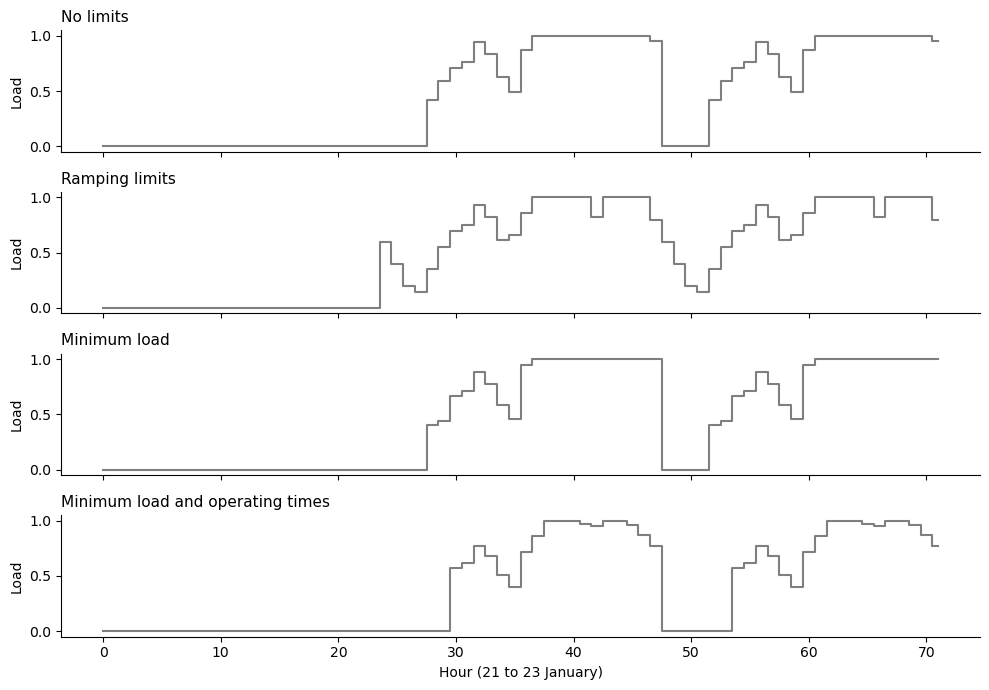

In [9]:
days = [20, 21, 22]  # days of the year, counted from 0
fig, axes = plt.subplots(
    len(operationPerVariant), 1, figsize=(10, 7), sharex=True, sharey=True
)
for ax, (variant, load) in zip(axes, operationPerVariant.items()):
    ax.step(
        range(72), load[days].flatten(), where="mid", color=COLORS["Gas power plants"]
    )
    ax.set_title(variant, loc="left")
    ax.set_ylabel("Load")
axes[-1].set_xlabel("Hour (21 to 23 January)")
fig.tight_layout()

- **Ramping limits:** within a day, the output never changes by more than 20 % of the capacity per hour. The plants start earlier and reduce their output more slowly. The jump from zero to 60 % at midnight between 21 and 22 January is not a mistake: the two days are represented by different typical days, and the ramping limit is not applied between consecutive days of the calendar. The ramping limits make the system about 3 billion Euro more expensive.
- **Minimum load:** the plants never run below 40 % of their capacity. Instead of running at a low output, they switch off and on more often: the number of starts rises from 92 to 147.
- **Minimum load and operating times:** the plants now start as often as without limits (92 times). On 22 January, they stay off for 6 hours instead of 4.

The two models with integer variables were only solved up to a gap of 1 %, which is about 6 billion Euro here. Their differences in cost are smaller than this gap and should not be interpreted; to compare costs, the gap would have to be much smaller, which takes much longer to solve.

## Things to try

- Use a `rampUpMax` of 0.05. How many hours does a gas power plant now need from zero to full load, and what does it cost?
- Increase `downTimeMin` to 12 hours.
- Combine the ramping limits with the minimum load.

The next notebook, [Flexible Conversions](45_flexible_conversions.ipynb), lets power plants choose between two fuels.